<a href="https://colab.research.google.com/github/shreyashkhedkar07/smart-city-traffic-flow-simulator/blob/main/Smart_City_Traffic_Flow_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart City Traffic Flow Simulator
### NumPy + Google Colab project

**Goal:** Simulate 30 days of hourly vehicle counts across 10 junctions, model morning and evening rush-hour peaks, identify congestion bottlenecks, visualize traffic patterns, and compare loop-based vs. vectorized computation.

**Data shape:** `(days, junctions, hours)` = `(30, 10, 24)` = **7,200 junction-hour records**.

This is a **synthetic educational simulation**, not a live traffic feed. The generated counts are designed to resemble daily traffic patterns and can be adjusted in the configuration cell.


## Project workflow
1. Import libraries and set a random seed for reproducibility.
2. Create a rush-hour curve and simulate hourly traffic using a Poisson model.
3. Aggregate traffic by junction and hour; find peak congestion windows with `argmax`.
4. Plot heatmaps and summaries.
5. Benchmark a loop-based calculation against a NumPy vectorized calculation.


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

DAYS = 30
JUNCTIONS = 10
HOURS = 24

print(f"Simulation dimensions: {DAYS} days × {JUNCTIONS} junctions × {HOURS} hours")
print(f"Total junction-hour records: {DAYS * JUNCTIONS * HOURS:,}")

Simulation dimensions: 30 days × 10 junctions × 24 hours
Total junction-hour records: 7,200


## 1. Build an hourly traffic-intensity curve

The baseline is lower overnight, rises during the morning commute, dips midday, and rises again during the evening commute. Each junction gets a different traffic multiplier so that some junctions are naturally busier than others.


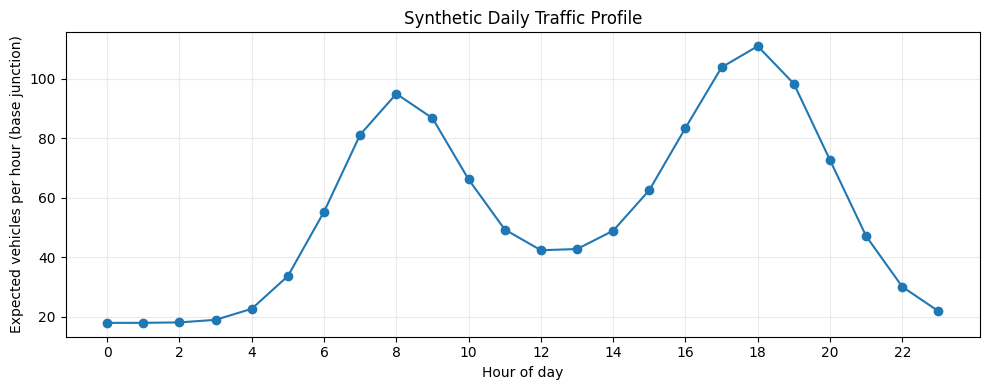

In [2]:
hours = np.arange(HOURS)

# Gaussian-shaped morning and evening peaks plus a low overnight baseline.
baseline = 18
morning_peak = 72 * np.exp(-0.5 * ((hours - 8) / 1.7) ** 2)
evening_peak = 88 * np.exp(-0.5 * ((hours - 18) / 2.0) ** 2)
midday_activity = 20 * np.exp(-0.5 * ((hours - 13) / 3.0) ** 2)

hourly_profile = baseline + morning_peak + evening_peak + midday_activity

plt.figure(figsize=(10, 4))
plt.plot(hours, hourly_profile, marker="o")
plt.xticks(range(0, 24, 2))
plt.xlabel("Hour of day")
plt.ylabel("Expected vehicles per hour (base junction)")
plt.title("Synthetic Daily Traffic Profile")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 2. Simulate 30 days of traffic

A Poisson distribution is suitable for a simple count model because it generates non-negative integer counts. The expected count (`lambda`) combines the hourly profile, each junction's relative busyness, and day-to-day variation.

For this project, weekends are assumed to have slightly lower traffic. This is a simplifying assumption and can be changed.


In [3]:
# Relative traffic volume for each junction (higher means busier).
junction_factors = np.array([0.82, 1.15, 0.95, 1.32, 0.72,
                             1.05, 1.22, 0.88, 1.42, 1.00])

# Day multipliers introduce modest variation across the 30 days.
day_factors = rng.normal(loc=1.0, scale=0.08, size=DAYS)
day_factors = np.clip(day_factors, 0.75, 1.25)

# Weekend adjustment: days 5 and 6 of each 7-day block are treated as weekends.
weekend_factors = np.ones(DAYS)
weekend_factors[np.arange(DAYS) % 7 >= 5] = 0.82

# Expected counts have shape (days, junctions, hours).
expected_counts = (
    day_factors[:, None, None]
    * weekend_factors[:, None, None]
    * junction_factors[None, :, None]
    * hourly_profile[None, None, :]
)

traffic = rng.poisson(lam=expected_counts).astype(np.int32)

assert traffic.shape == (DAYS, JUNCTIONS, HOURS)
assert np.issubdtype(traffic.dtype, np.integer)
assert np.all(traffic >= 0)

print("Traffic array shape:", traffic.shape)
print("Minimum count:", traffic.min())
print("Maximum count:", traffic.max())
print("Mean vehicles per junction-hour:", round(float(traffic.mean()), 2))

Traffic array shape: (30, 10, 24)
Minimum count: 3
Maximum count: 205
Mean vehicles per junction-hour: 55.55


## 3. Aggregate traffic and find bottlenecks

We will calculate:
- Total vehicles counted at each junction over all 30 days.
- Average traffic for each hour of the day.
- The busiest hour for each junction.
- The busiest junction overall.

`axis` tells NumPy which dimension to aggregate over. The original array uses `(days, junctions, hours)`.


In [4]:
# Total across days and hours -> one total per junction.
junction_totals = traffic.sum(axis=(0, 2))

# Average over days and junctions -> one average per hour.
hourly_average = traffic.mean(axis=(0, 1))

# Average across days -> junction-by-hour matrix.
junction_hour_average = traffic.mean(axis=0)

# Peak hour index for each junction.
peak_hour_by_junction = junction_hour_average.argmax(axis=1)

summary = pd.DataFrame({
    "Junction": [f"Junction {i+1}" for i in range(JUNCTIONS)],
    "Total vehicles (30 days)": junction_totals,
    "Average vehicles/hour": traffic.mean(axis=(0, 2)),
    "Peak hour": peak_hour_by_junction,
    "Peak-hour average count": junction_hour_average.max(axis=1)
}).sort_values("Total vehicles (30 days)", ascending=False).reset_index(drop=True)

display(summary.round(2))

busiest_junction_idx = int(junction_totals.argmax())
busiest_hour_idx = int(hourly_average.argmax())

print(f"Busiest junction: Junction {busiest_junction_idx + 1}")
print(f"Busiest hour overall: {busiest_hour_idx:02d}:00")
print(f"Total simulated vehicles across all junctions and days: {traffic.sum():,}")

,Junction,Total vehicles (30 days),Average vehicles/hour,Peak hour,Peak-hour average count
0,Junction 9,54183,75.25,18,148.90
1,Junction 4,49866,69.26,18,137.77
2,Junction 7,46463,64.53,18,128.70
3,Junction 2,43409,60.29,18,122.33
4,Junction 6,39742,55.20,17,107.73
5,Junction 10,37922,52.67,18,105.60
6,Junction 3,36146,50.20,18,100.07
7,Junction 8,33848,47.01,18,92.07
8,Junction 1,31086,43.18,18,89.90
9,Junction 5,27308,37.93,18,78.37


Busiest junction: Junction 9
Busiest hour overall: 18:00
Total simulated vehicles across all junctions and days: 399,973


## 4. Visualize the results

The heatmap shows average vehicles per hour for each junction. Brighter cells indicate heavier traffic and help reveal where/when congestion is most likely in this simulated dataset.


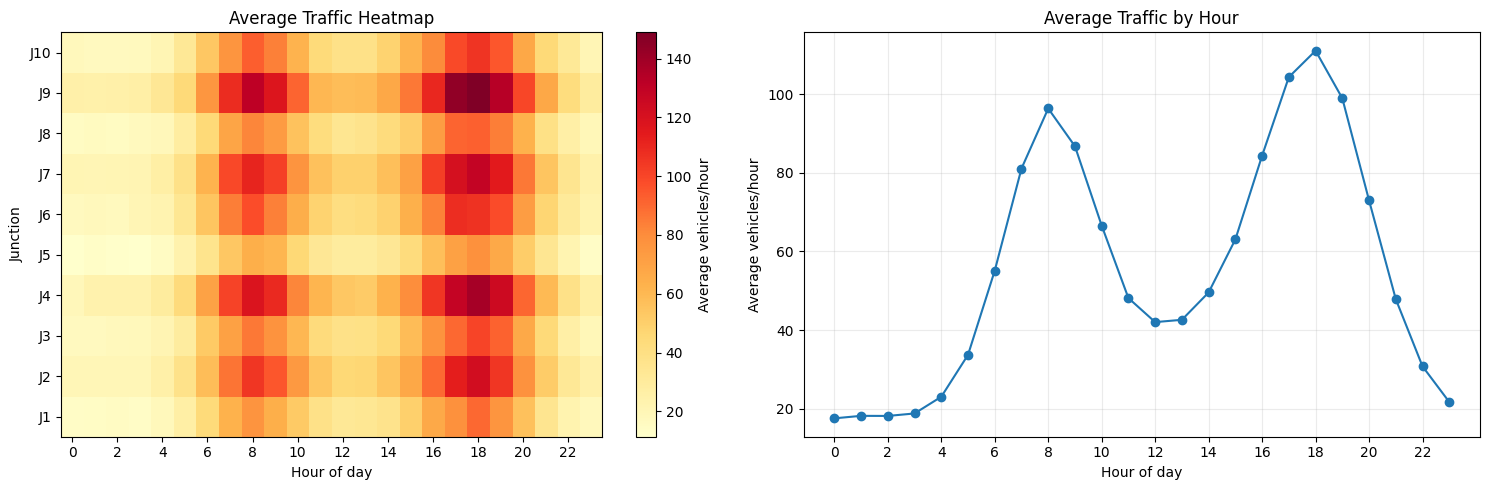

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

im = axes[0].imshow(junction_hour_average, aspect="auto", origin="lower", cmap="YlOrRd")
axes[0].set_title("Average Traffic Heatmap")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Junction")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_yticks(range(JUNCTIONS))
axes[0].set_yticklabels([f"J{i+1}" for i in range(JUNCTIONS)])
fig.colorbar(im, ax=axes[0], label="Average vehicles/hour")

axes[1].plot(hours, hourly_average, marker="o")
axes[1].set_title("Average Traffic by Hour")
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("Average vehicles/hour")
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 5. Identify the top congestion windows

This ranks the junction-hour combinations by their average count across the simulated days. It is a simple proxy for potential bottlenecks; real congestion analysis would also need road capacity, vehicle speed, queue length, and signal timing.


In [6]:
rows = []
for j in range(JUNCTIONS):
    for h in range(HOURS):
        rows.append({
            "Junction": f"Junction {j+1}",
            "Hour": f"{h:02d}:00",
            "Hour index": h,
            "Average vehicles/hour": junction_hour_average[j, h]
        })

bottlenecks = pd.DataFrame(rows).sort_values(
    "Average vehicles/hour", ascending=False
).head(10).reset_index(drop=True)

display(bottlenecks.round(2))

,Junction,Hour,Hour index,Average vehicles/hour
0,Junction 9,18:00,18,148.90
1,Junction 9,17:00,17,143.60
2,Junction 4,18:00,18,137.77
3,Junction 9,19:00,19,132.87
4,Junction 9,08:00,8,130.87
5,Junction 7,18:00,18,128.70
6,Junction 4,17:00,17,128.27
7,Junction 4,19:00,19,124.70
8,Junction 2,18:00,18,122.33
9,Junction 7,17:00,17,120.93


## 6. Compare loop-based and vectorized computation

Both approaches calculate the mean traffic count for every junction-hour cell across all days. The results should match; vectorization usually avoids Python-level loops and can be much faster for larger arrays.

Timing varies by machine and run, so treat the benchmark as an experiment rather than a guaranteed performance claim.


In [7]:
def mean_with_loops(data):
    days, junctions, hours = data.shape
    result = np.zeros((junctions, hours), dtype=float)
    for j in range(junctions):
        for h in range(hours):
            total = 0
            for d in range(days):
                total += data[d, j, h]
            result[j, h] = total / days
    return result

def mean_vectorized(data):
    return data.mean(axis=0)

# Warm-up and correctness check.
loop_result = mean_with_loops(traffic)
vector_result = mean_vectorized(traffic)
np.testing.assert_allclose(loop_result, vector_result, rtol=1e-12, atol=1e-12)

# Repeat several times for a more stable timing estimate.
REPEATS = 20

start = time.perf_counter()
for _ in range(REPEATS):
    mean_with_loops(traffic)
loop_seconds = (time.perf_counter() - start) / REPEATS

start = time.perf_counter()
for _ in range(REPEATS):
    mean_vectorized(traffic)
vector_seconds = (time.perf_counter() - start) / REPEATS

speedup = loop_seconds / vector_seconds if vector_seconds > 0 else float("inf")

benchmark = pd.DataFrame({
    "Method": ["Nested Python loops", "NumPy vectorized mean"],
    "Average runtime (seconds)": [loop_seconds, vector_seconds]
})
display(benchmark)

print(f"Approximate speedup: {speedup:.2f}×")
print("Correctness check passed: loop and vectorized results match.")

,Method,Average runtime (seconds)
0,Nested Python loops,0.002712
1,NumPy vectorized mean,0.000049


Approximate speedup: 55.72×
Correctness check passed: loop and vectorized results match.


## 7. Export the simulated data

This creates a flat CSV with one row per day, junction, and hour, which is convenient for spreadsheets or later analysis.


In [8]:
day_idx, junction_idx, hour_idx = np.indices(traffic.shape)

traffic_df = pd.DataFrame({
    "Day": day_idx.ravel() + 1,
    "Junction": (junction_idx.ravel() + 1),
    "Hour": hour_idx.ravel(),
    "Vehicle_Count": traffic.ravel()
})

csv_path = "smart_city_traffic_data.csv"
traffic_df.to_csv(csv_path, index=False)

print(f"Saved {len(traffic_df):,} rows to {csv_path}")
display(traffic_df.head(10))

Saved 7,200 rows to smart_city_traffic_data.csv


,Day,Junction,Hour,Vehicle_Count
0,1,1,0,13
1,1,1,1,15
2,1,1,2,10
3,1,1,3,12
4,1,1,4,18
5,1,1,5,32
6,1,1,6,54
7,1,1,7,65
8,1,1,8,85
9,1,1,9,65


## 8. Conclusions

Use the output from your actual run to write the final observations. A suitable conclusion format is:

- **Busiest junction:** report the junction printed by the summary.
- **Busiest hour:** report the hour with the highest average count.
- **Rush-hour pattern:** check whether the morning and evening peaks appear in the line plot.
- **Bottleneck candidates:** use the top rows in the bottleneck table.
- **NumPy learning outcome:** `sum`, `mean`, `argmax`, broadcasting, array shape, and vectorization reduce the need for manual loops.

### Limitations
- Counts are synthetic and generated with a Poisson model.
- Junction capacity, traffic lights, accidents, weather, and vehicle speeds are not modeled.
- Weekend and rush-hour patterns are illustrative assumptions, not measured city data.
